# 🥇 Camada Gold: Feature Store, Engenharia de Atributos e Análise Exploratória dos Preditores
## Suíte de 10 Representações Gráficas para a Dissertação de Mestrado Profissional

* **Instituição de Ensino:** Instituto Federal de São Paulo (IFSP) – Campus Itaquaquecetuba
* **Localização:** Rua Primeiro de Maio, nº 500, Bairro Estação, Itaquaquecetuba - SP
* **Origem dos Dados:** Camada Silver (`dados/silver/silver_fato_diaria.parquet`)
* **Destino dos Dados:** Camada Gold (`dados/gold/gold_dataset_ml_limpo.parquet` e `gold_feature_store_completa.parquet`)
* **Público:** Produto Técnico / Dissertação de Mestrado Profissional

---
### 🧭 Estrutura da Suíte Gráfica da Camada Gold (10 Figuras)
1. **Figura 26:** Ranking de Correlação Linear de Pearson (Top 20 Features vs. Consumo Real)
2. **Figura 27:** Importância Relativa dos Preditores via Random Forest Regressor (Gini %)
3. **Figura 28:** Dependência Não-Linear via Informação Mútua (Mutual Information)
4. **Figura 29:** Diagnóstico de Aderência do Preditor Líder (Consumo no Mesmo Dia da Semana Anterior)
5. **Figura 30:** Diagnóstico da Âncora de Curto Prazo (Média Móvel dos Últimos 5 Dias Úteis)
6. **Figura 31:** Matriz de Multicolinearidade entre os Principais Preditores da Feature Store
7. **Figura 32:** Avaliação Preditiva dos Scores de Atratividade Culinária (Proteína e Preparo)
8. **Figura 33:** Efeito do Índice Composto de Adversidade Climática sobre o Consumo
9. **Figura 34:** Mapeamento Trigonométrico Cíclico de Sazonalidade (Seno/Cosseno de Dia e Mês)
10. **Figura 35:** Diagnóstico da Partição Temporal de Modelagem (Treino, Validação e Teste Out-of-Time)

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import mutual_info_regression

FIG_DIR = "../reports/figuras"
os.makedirs(FIG_DIR, exist_ok=True)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['axes.edgecolor'] = '#444444'
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11

print("Ambiente configurado com sucesso!")

Ambiente configurado com sucesso!


In [2]:
path_gold_ml = "../dados/gold/gold_dataset_ml_limpo.parquet"
df_gold = pd.read_parquet(path_gold_ml)
df_gold["data_dt"] = pd.to_datetime(df_gold["data_iso"])
# Corte estrito de qualificação: 31/08/2026
df_gold = df_gold[df_gold["data_iso"] <= "2026-08-31"].copy()

print(f"Total de registros na base ML limpa: {len(df_gold)} dias regulares")
print(f"Total de atributos na Feature Store: {len(df_gold.columns)}")

Total de registros na base ML limpa: 568 dias regulares
Total de atributos na Feature Store: 106


In [3]:
features_memoria = [
    'lag_1_dia_letivo', 'lag_2_dia_letivo', 'lag_5_dias_letivos', 'lag_10_dias_letivos',
    'consumo_mesmo_dia_sem_passada', 'consumo_mesmo_dia_sem_retrasada',
    'media_movel_5d', 'desvio_movel_5d', 'media_movel_10d', 'media_movel_20d', 'amplitude_movel_5d'
]

features_calendario = [
    'dia_da_semana_num', 'dia_do_mes', 'mes', 'semana_do_ano',
    'is_segunda', 'is_terca', 'is_quarta', 'is_quinta', 'is_sexta',
    'sin_dia_semana', 'cos_dia_semana', 'sin_mes', 'cos_mes',
    'is_inicio_mes', 'is_fim_mes'
]

features_cardapio = [
    'proteina_frango', 'proteina_bovina', 'proteina_suina', 'proteina_peixe', 'proteina_feijoada', 'proteina_mista',
    'score_atratividade_proteina', 'score_atratividade_preparo'
]

features_clima = [
    'precipitation_sum', 'precipitation_hours', 'temperature_2m_max', 'temperature_2m_min',
    'amplitude_termica', 'wind_speed_10m_max', 'indice_adversidade_climatica',
    'is_chuva_forte', 'is_chuva_persistente', 'is_dia_frio', 'is_dia_muito_quente'
]

todas_features = features_memoria + features_calendario + features_cardapio + features_clima
df_clean = df_gold.dropna(subset=['consumo'] + todas_features).copy()
print(f"Registros completos para análise estatística: {len(df_clean)}")

Registros completos para análise estatística: 372


### 1. Figura 26: Ranking de Correlação Linear das Features com o Consumo Real

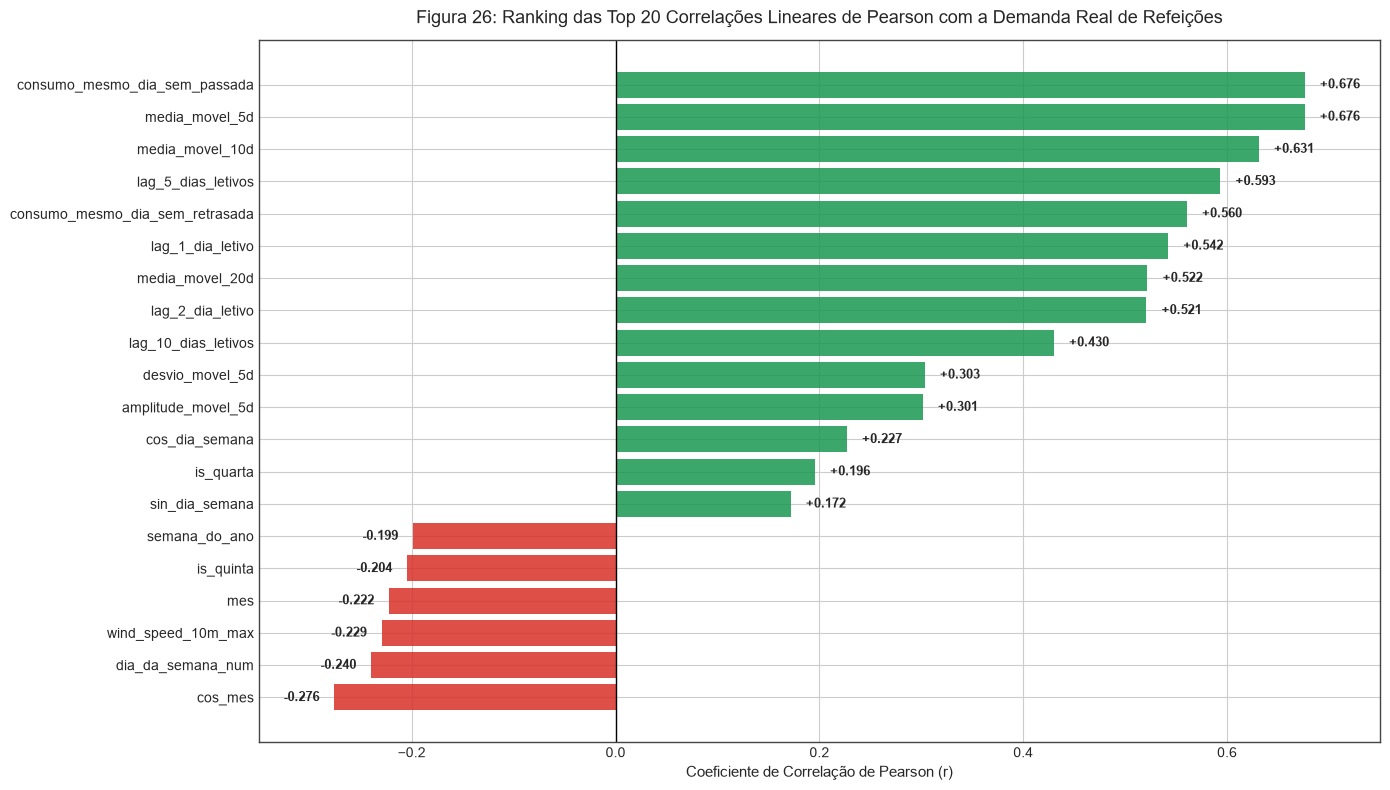

In [4]:
# Fig 26: Top 20 Correlações de Pearson
corrs = df_clean[todas_features].apply(lambda s: s.corr(df_clean['consumo'])).sort_values()
top_neg = corrs.head(6)
top_pos = corrs.tail(14)
destaque = pd.concat([top_neg, top_pos])

fig, ax = plt.subplots(figsize=(14, 8))
cores = ['#d73027' if v < 0 else '#1a9850' for v in destaque.values]

ax.barh(destaque.index, destaque.values, color=cores, alpha=0.85)
ax.axvline(0, color='black', lw=1)
for i, v in enumerate(destaque.values):
    ax.text(v + (0.015 if v >= 0 else -0.05), i, f"{v:+.3f}", va='center', fontweight='bold', fontsize=9)

ax.set_title("Figura 26: Ranking das Top 20 Correlações Lineares de Pearson com a Demanda Real de Refeições", fontsize=13, pad=12)
ax.set_xlabel("Coeficiente de Correlação de Pearson (r)")
ax.set_xlim(-0.35, 0.75)

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig26_ranking_correlacao_features_gold.png", dpi=300, bbox_inches='tight')
plt.show()

### 2. Figura 27: Importância Relativa via Random Forest Regressor

C:\Users\miche\AppData\Local\Temp\ipykernel_34616\1338369830.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=ax, x=rf_imp.values, y=rf_imp.index, palette="Blues_r")


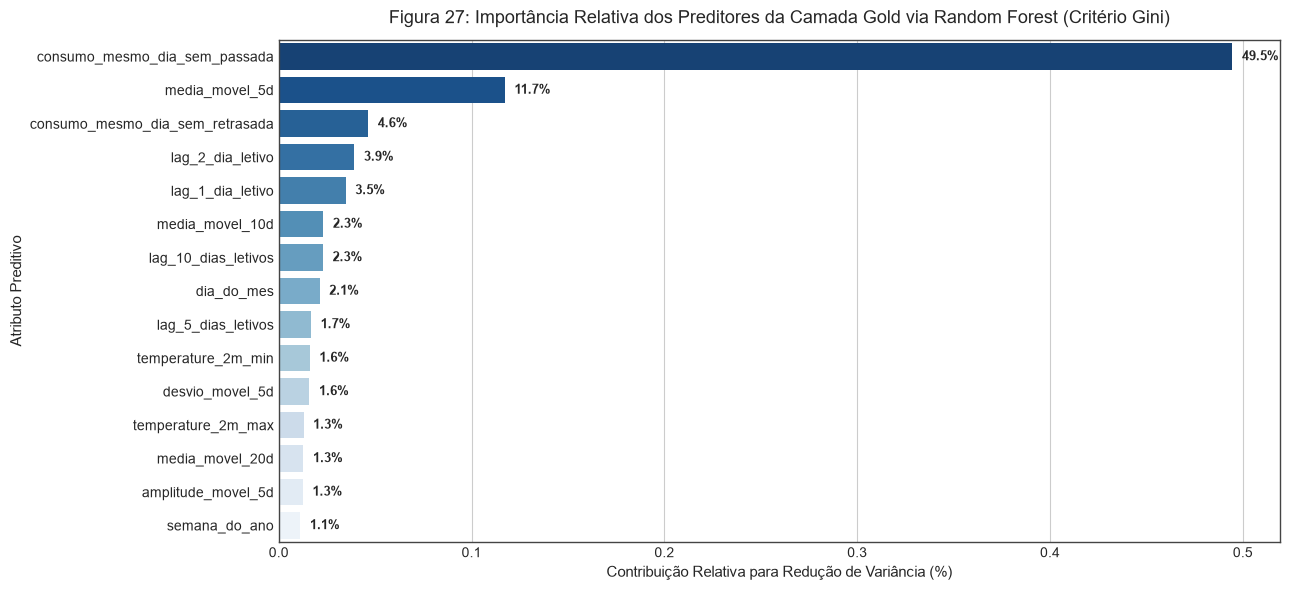

In [5]:
# Fig 27: Random Forest Feature Importance (Top 15)
X = df_clean[todas_features]
y = df_clean['consumo']

rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X, y)

rf_imp = pd.Series(rf.feature_importances_, index=todas_features).sort_values(ascending=False).head(15)

fig, ax = plt.subplots(figsize=(13, 6))
sns.barplot(ax=ax, x=rf_imp.values, y=rf_imp.index, palette="Blues_r")

for i, v in enumerate(rf_imp.values):
    ax.text(v + 0.005, i, f"{v*100:.1f}%", va='center', fontweight='bold', fontsize=9)

ax.set_title("Figura 27: Importância Relativa dos Preditores da Camada Gold via Random Forest (Critério Gini)", fontsize=13, pad=12)
ax.set_xlabel("Contribuição Relativa para Redução de Variância (%)")
ax.set_ylabel("Atributo Preditivo")

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig27_random_forest_importance.png", dpi=300, bbox_inches='tight')
plt.show()

### 3. Figura 28: Ganho de Informação Não-Linear (Mutual Information)

C:\Users\miche\AppData\Local\Temp\ipykernel_34616\4145635519.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=ax, x=mi_imp.values, y=mi_imp.index, palette="Greens_r")


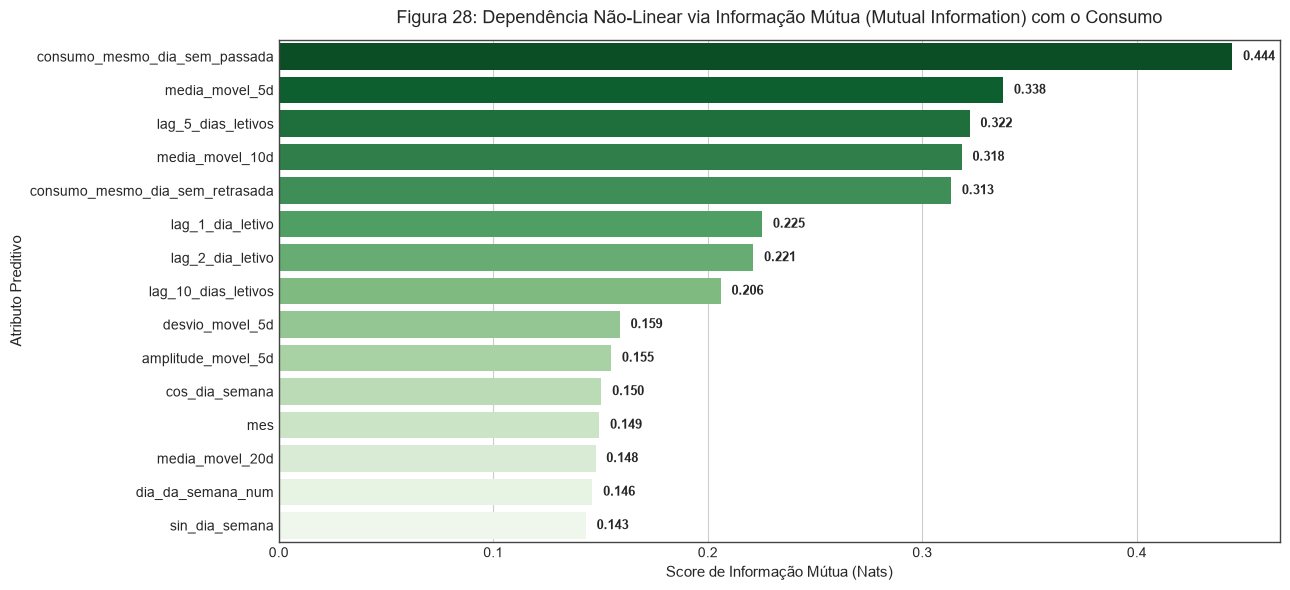

In [6]:
# Fig 28: Mutual Information (Top 15)
mi = mutual_info_regression(X, y, random_state=42)
mi_imp = pd.Series(mi, index=todas_features).sort_values(ascending=False).head(15)

fig, ax = plt.subplots(figsize=(13, 6))
sns.barplot(ax=ax, x=mi_imp.values, y=mi_imp.index, palette="Greens_r")

for i, v in enumerate(mi_imp.values):
    ax.text(v + 0.005, i, f"{v:.3f}", va='center', fontweight='bold', fontsize=9)

ax.set_title("Figura 28: Dependência Não-Linear via Informação Mútua (Mutual Information) com o Consumo", fontsize=13, pad=12)
ax.set_xlabel("Score de Informação Mútua (Nats)")
ax.set_ylabel("Atributo Preditivo")

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig28_mutual_information_importance.png", dpi=300, bbox_inches='tight')
plt.show()

### 4. Figura 29: Diagnóstico de Aderência do Preditor Líder (Mesmo Dia da Semana Passada)

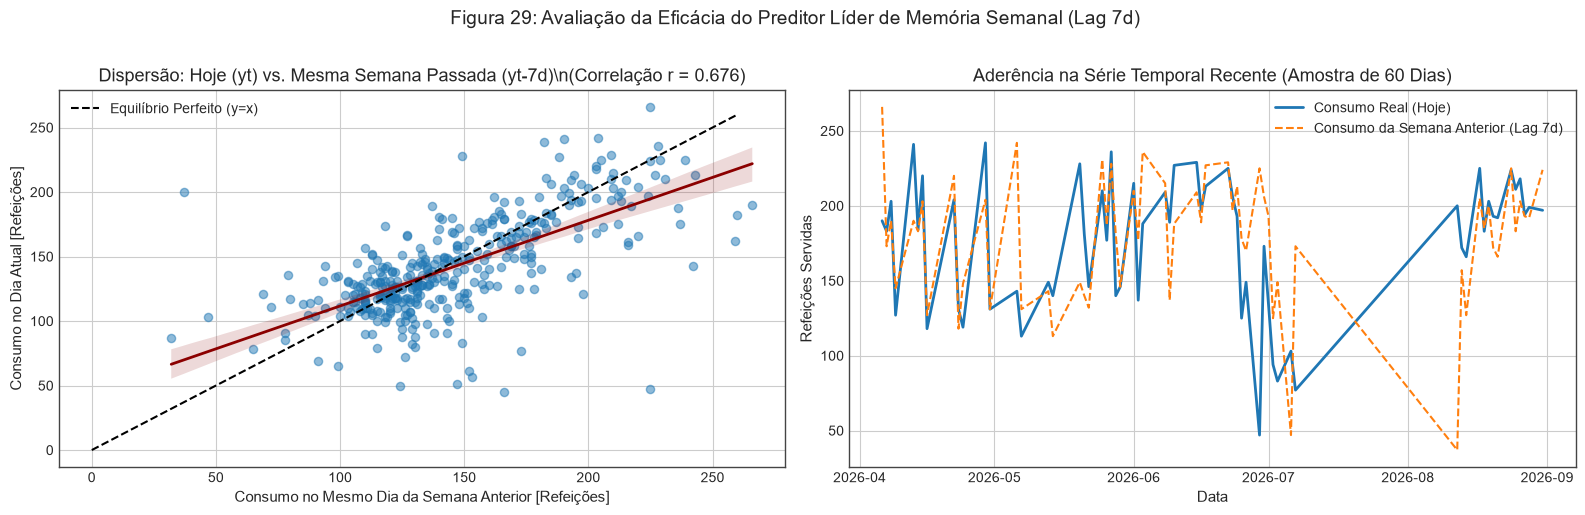

In [7]:
# Fig 29: Lag 7 (Mesmo Dia da Semana Passada)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Dispersão
sns.regplot(ax=axes[0], data=df_clean, x='consumo_mesmo_dia_sem_passada', y='consumo',
            scatter_kws={'alpha': 0.5, 'color': '#1f77b4', 's': 35}, line_kws={'color': 'darkred', 'lw': 2})
axes[0].plot([0, 260], [0, 260], 'k--', label='Equilíbrio Perfeito (y=x)')
axes[0].set_title(f"Dispersão: Hoje (yt) vs. Mesma Semana Passada (yt-7d)\\n(Correlação r = {df_clean['consumo'].corr(df_clean['consumo_mesmo_dia_sem_passada']):.3f})")
axes[0].set_xlabel("Consumo no Mesmo Dia da Semana Anterior [Refeições]")
axes[0].set_ylabel("Consumo no Dia Atual [Refeições]")
axes[0].legend(loc='upper left')

# Série temporal sobreposta (amostra de 60 dias)
amostra = df_clean.tail(60)
axes[1].plot(amostra['data_dt'], amostra['consumo'], color='#1f77b4', lw=2, label='Consumo Real (Hoje)')
axes[1].plot(amostra['data_dt'], amostra['consumo_mesmo_dia_sem_passada'], color='#ff7f0e', linestyle='--', lw=1.5, label='Consumo da Semana Anterior (Lag 7d)')
axes[1].set_title("Aderência na Série Temporal Recente (Amostra de 60 Dias)")
axes[1].set_xlabel("Data")
axes[1].set_ylabel("Refeições Servidas")
axes[1].legend(loc='upper right')

plt.suptitle("Figura 29: Avaliação da Eficácia do Preditor Líder de Memória Semanal (Lag 7d)", fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig29_aderencia_lag_mesma_semana.png", dpi=300, bbox_inches='tight')
plt.show()

### 5. Figura 30: Diagnóstico da Âncora de Curto Prazo (Média Móvel de 5 Dias)

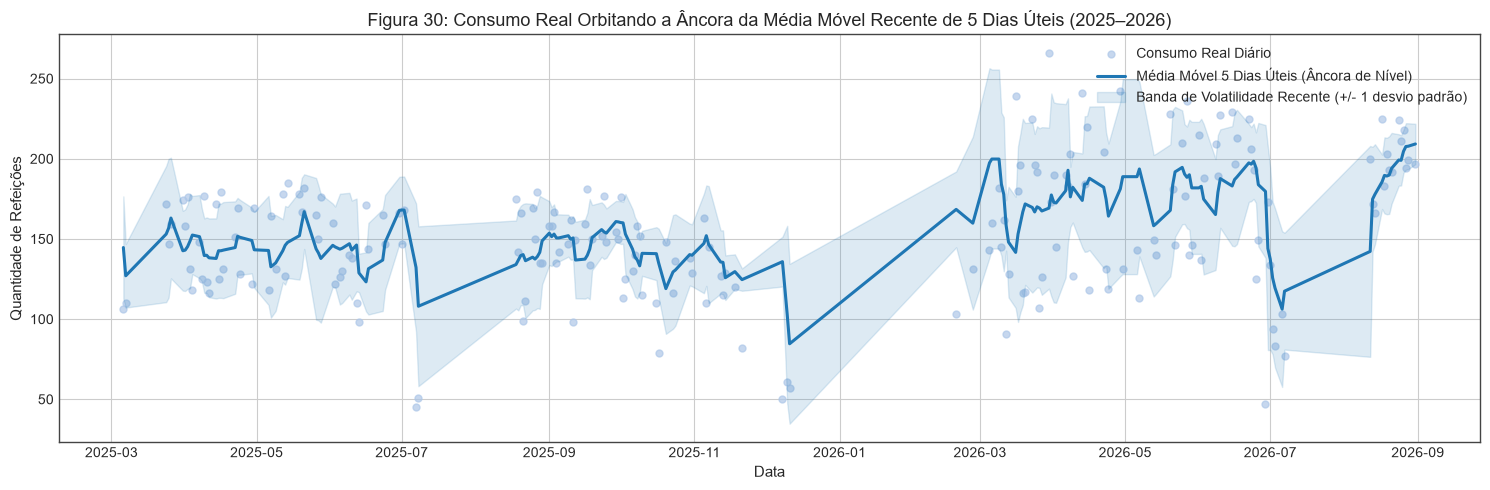

In [8]:
# Fig 30: Média Móvel 5d como Âncora
fig, ax = plt.subplots(figsize=(15, 5))

sub_tempo = df_clean[df_clean['ano'] >= 2025].copy()
ax.scatter(sub_tempo['data_dt'], sub_tempo['consumo'], color='#aec7e8', s=25, alpha=0.7, label='Consumo Real Diário')
ax.plot(sub_tempo['data_dt'], sub_tempo['media_movel_5d'], color='#1f77b4', lw=2.2, label='Média Móvel 5 Dias Úteis (Âncora de Nível)')
ax.fill_between(sub_tempo['data_dt'], 
                sub_tempo['media_movel_5d'] - sub_tempo['desvio_movel_5d'].fillna(0),
                sub_tempo['media_movel_5d'] + sub_tempo['desvio_movel_5d'].fillna(0),
                color='#1f77b4', alpha=0.15, label='Banda de Volatilidade Recente (+/- 1 desvio padrão)')

ax.set_title("Figura 30: Consumo Real Orbitando a Âncora da Média Móvel Recente de 5 Dias Úteis (2025–2026)", fontsize=13)
ax.set_xlabel("Data")
ax.set_ylabel("Quantidade de Refeições")
ax.legend(loc='upper right')

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig30_aderencia_media_movel_5d.png", dpi=300, bbox_inches='tight')
plt.show()

### 6. Figura 31: Matriz de Multicolinearidade entre os Preditores da Camada Gold

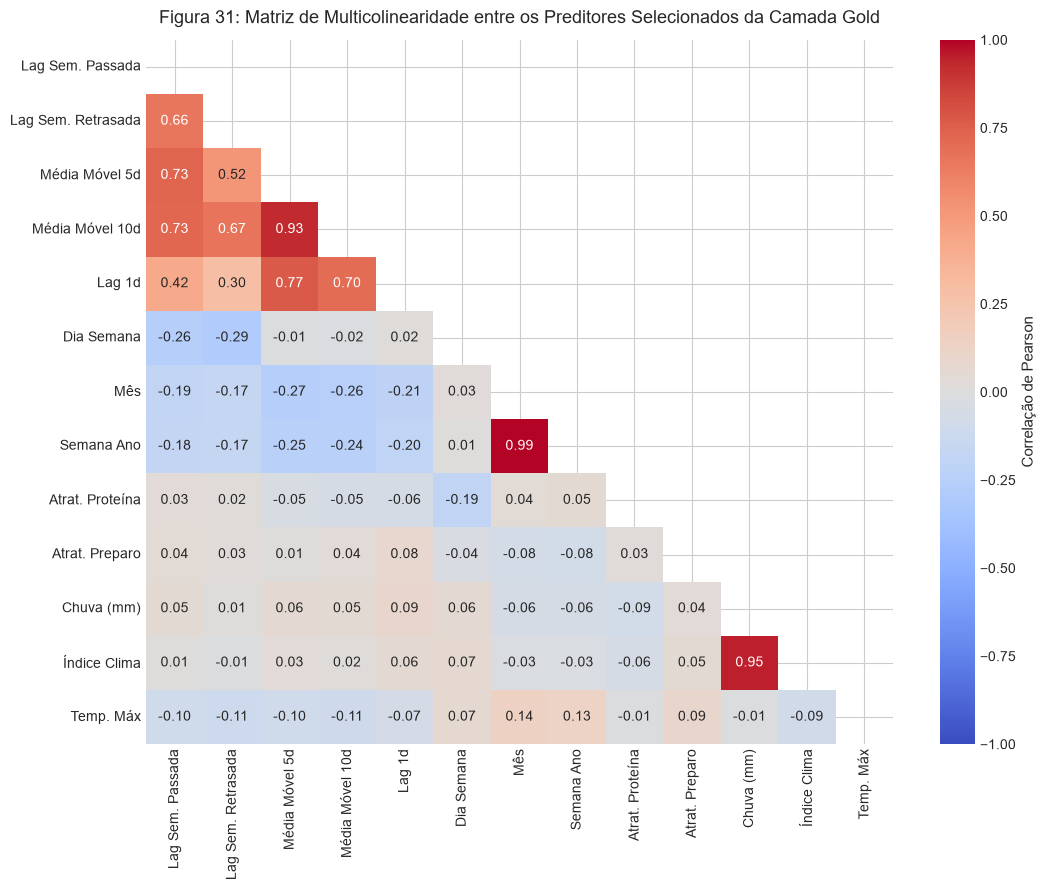

In [9]:
# Fig 31: Multicolinearidade entre Preditores Principais
top_features_analise = [
    'consumo_mesmo_dia_sem_passada', 'consumo_mesmo_dia_sem_retrasada',
    'media_movel_5d', 'media_movel_10d', 'lag_1_dia_letivo',
    'dia_da_semana_num', 'mes', 'semana_do_ano',
    'score_atratividade_proteina', 'score_atratividade_preparo',
    'precipitation_sum', 'indice_adversidade_climatica', 'temperature_2m_max'
]

nomes_legiveis = [
    'Lag Sem. Passada', 'Lag Sem. Retrasada',
    'Média Móvel 5d', 'Média Móvel 10d', 'Lag 1d',
    'Dia Semana', 'Mês', 'Semana Ano',
    'Atrat. Proteína', 'Atrat. Preparo',
    'Chuva (mm)', 'Índice Clima', 'Temp. Máx'
]

corr_pred = df_clean[top_features_analise].corr()
corr_pred.columns = nomes_legiveis
corr_pred.index = nomes_legiveis

fig, ax = plt.subplots(figsize=(11, 9))
mask = np.triu(np.ones_like(corr_pred, dtype=bool))
sns.heatmap(corr_pred, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax, cbar_kws={'label': 'Correlação de Pearson'})
ax.set_title("Figura 31: Matriz de Multicolinearidade entre os Preditores Selecionados da Camada Gold", fontsize=13, pad=12)

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig31_multicolinearidade_heatmap.png", dpi=300, bbox_inches='tight')
plt.show()

### 7. Figura 32: Avaliação Preditiva dos Scores de Atratividade Culinária

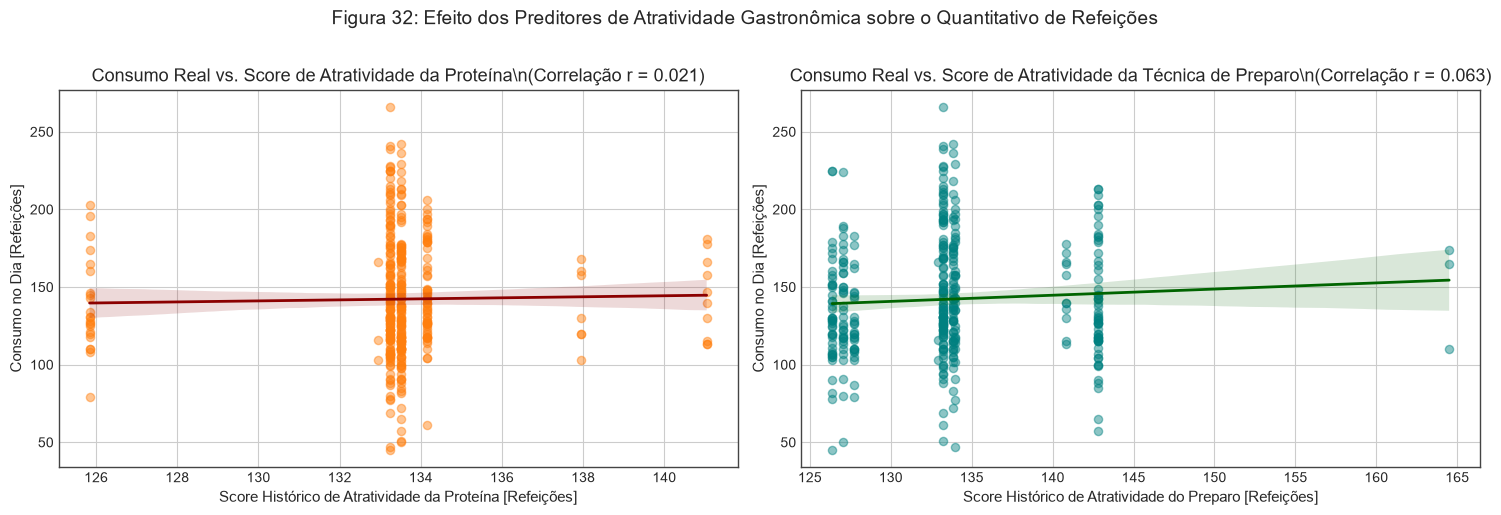

In [10]:
# Fig 32: Scores de Atratividade do Cardápio
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Atratividade Proteína
sns.regplot(ax=axes[0], data=df_clean, x='score_atratividade_proteina', y='consumo',
            scatter_kws={'alpha': 0.45, 'color': '#ff7f0e', 's': 35}, line_kws={'color': 'darkred', 'lw': 2})
axes[0].set_title(f"Consumo Real vs. Score de Atratividade da Proteína\\n(Correlação r = {df_clean['consumo'].corr(df_clean['score_atratividade_proteina']):.3f})")
axes[0].set_xlabel("Score Histórico de Atratividade da Proteína [Refeições]")
axes[0].set_ylabel("Consumo no Dia [Refeições]")

# Atratividade Preparo
sns.regplot(ax=axes[1], data=df_clean, x='score_atratividade_preparo', y='consumo',
            scatter_kws={'alpha': 0.45, 'color': 'teal', 's': 35}, line_kws={'color': 'darkgreen', 'lw': 2})
axes[1].set_title(f"Consumo Real vs. Score de Atratividade da Técnica de Preparo\\n(Correlação r = {df_clean['consumo'].corr(df_clean['score_atratividade_preparo']):.3f})")
axes[1].set_xlabel("Score Histórico de Atratividade do Preparo [Refeições]")
axes[1].set_ylabel("Consumo no Dia [Refeições]")

plt.suptitle("Figura 32: Efeito dos Preditores de Atratividade Gastronômica sobre o Quantitativo de Refeições", fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig32_atratividade_cardapio_scores.png", dpi=300, bbox_inches='tight')
plt.show()

### 8. Figura 33: Efeito do Índice Composto de Adversidade Climática

C:\Users\miche\AppData\Local\Temp\ipykernel_34616\1727342962.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(ax=axes[1], data=df_clean, x='faixa_adversidade', y='consumo', palette='Blues_d')


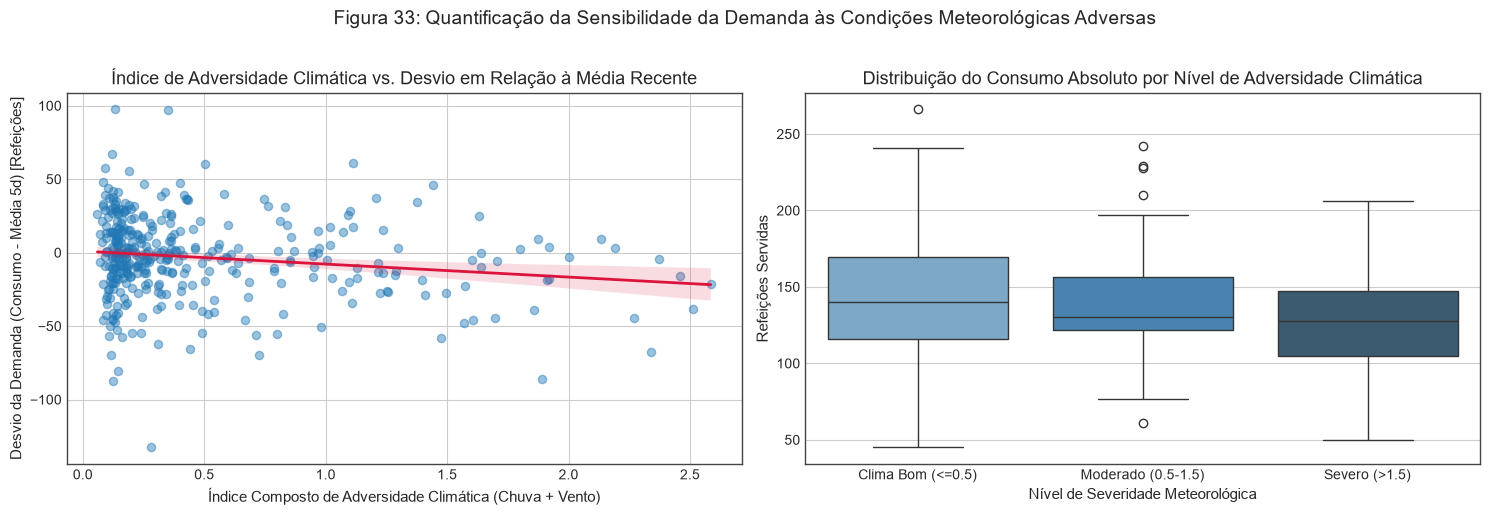

In [11]:
# Fig 33: Adversidade Climática vs Resíduo de Demanda
# Resíduo em relação à média recente de 5 dias (o quanto o consumo cai além do esperado)
df_clean['desvio_vs_media_5d'] = df_clean['consumo'] - df_clean['media_movel_5d']

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Dispersão
sns.regplot(ax=axes[0], data=df_clean, x='indice_adversidade_climatica', y='desvio_vs_media_5d',
            scatter_kws={'alpha': 0.45, 'color': '#1f77b4', 's': 35}, line_kws={'color': 'crimson', 'lw': 2})
axes[0].set_title("Índice de Adversidade Climática vs. Desvio em Relação à Média Recente")
axes[0].set_xlabel("Índice Composto de Adversidade Climática (Chuva + Vento)")
axes[0].set_ylabel("Desvio da Demanda (Consumo - Média 5d) [Refeições]")

# Boxplot por faixa de adversidade
df_clean['faixa_adversidade'] = pd.cut(df_clean['indice_adversidade_climatica'], bins=[-0.1, 0.5, 1.5, 5.0], labels=['Clima Bom (<=0.5)', 'Moderado (0.5-1.5)', 'Severo (>1.5)'])
sns.boxplot(ax=axes[1], data=df_clean, x='faixa_adversidade', y='consumo', palette='Blues_d')
axes[1].set_title("Distribuição do Consumo Absoluto por Nível de Adversidade Climática")
axes[1].set_xlabel("Nível de Severidade Meteorológica")
axes[1].set_ylabel("Refeições Servidas")

plt.suptitle("Figura 33: Quantificação da Sensibilidade da Demanda às Condições Meteorológicas Adversas", fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig33_adversidade_climatica_residuos.png", dpi=300, bbox_inches='tight')
plt.show()

### 9. Figura 34: Mapeamento Cíclico Trigonométrico de Sazonalidade

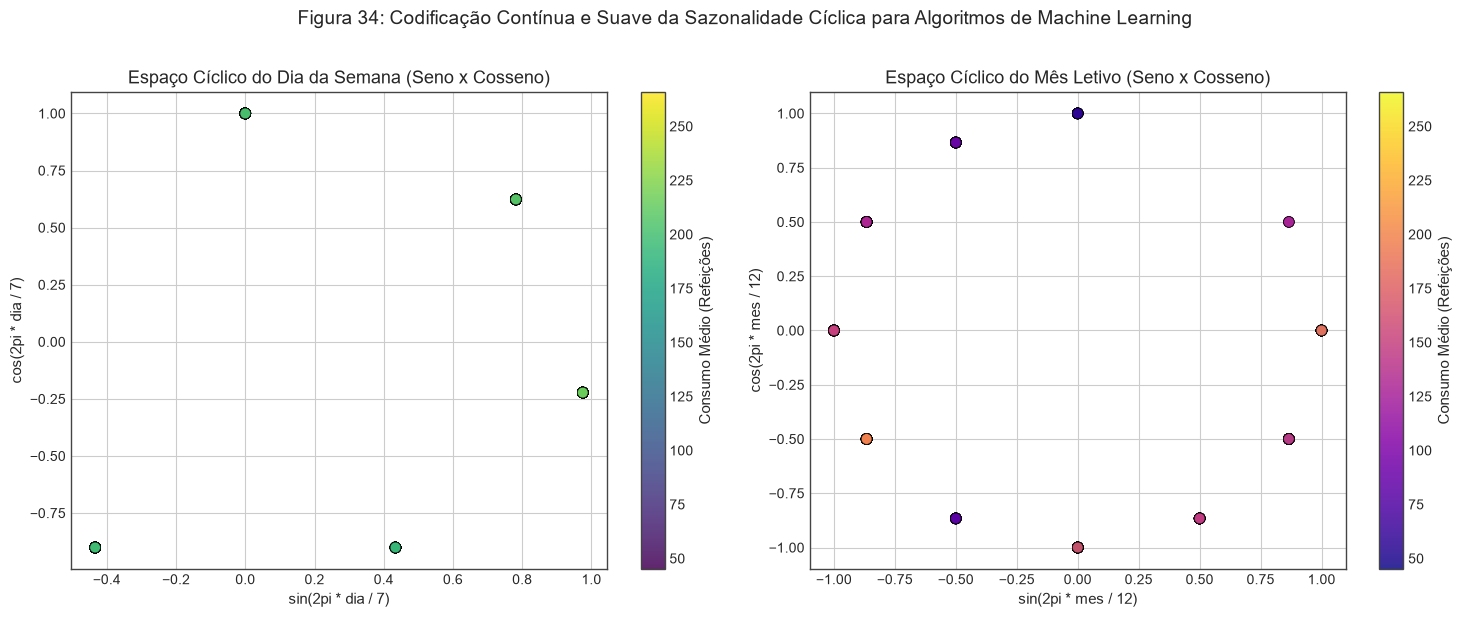

In [12]:
# Fig 34: Espaço Trigonométrico de Sazonalidade
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Dia da semana (Seno x Cosseno)
scatter1 = axes[0].scatter(df_clean['sin_dia_semana'], df_clean['cos_dia_semana'], 
                          c=df_clean['consumo'], cmap='viridis', s=60, alpha=0.85, edgecolor='black', lw=0.5)
cbar1 = plt.colorbar(scatter1, ax=axes[0])
cbar1.set_label('Consumo Médio (Refeições)')
axes[0].set_title("Espaço Cíclico do Dia da Semana (Seno x Cosseno)")
axes[0].set_xlabel("sin(2pi * dia / 7)")
axes[0].set_ylabel("cos(2pi * dia / 7)")

# Mês do ano (Seno x Cosseno)
scatter2 = axes[1].scatter(df_clean['sin_mes'], df_clean['cos_mes'], 
                          c=df_clean['consumo'], cmap='plasma', s=60, alpha=0.85, edgecolor='black', lw=0.5)
cbar2 = plt.colorbar(scatter2, ax=axes[1])
cbar2.set_label('Consumo Médio (Refeições)')
axes[1].set_title("Espaço Cíclico do Mês Letivo (Seno x Cosseno)")
axes[1].set_xlabel("sin(2pi * mes / 12)")
axes[1].set_ylabel("cos(2pi * mes / 12)")

plt.suptitle("Figura 34: Codificação Contínua e Suave da Sazonalidade Cíclica para Algoritmos de Machine Learning", fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig34_codificacao_ciclica_calendario.png", dpi=300, bbox_inches='tight')
plt.show()

### 10. Figura 35: Diagnóstico da Partição Temporal de Modelagem (Splits)

C:\Users\miche\AppData\Local\Temp\ipykernel_34616\2655507361.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(ax=axes[1], data=df_clean, x='split_modelagem', y='consumo', order=ordem_splits, palette=cores_split)


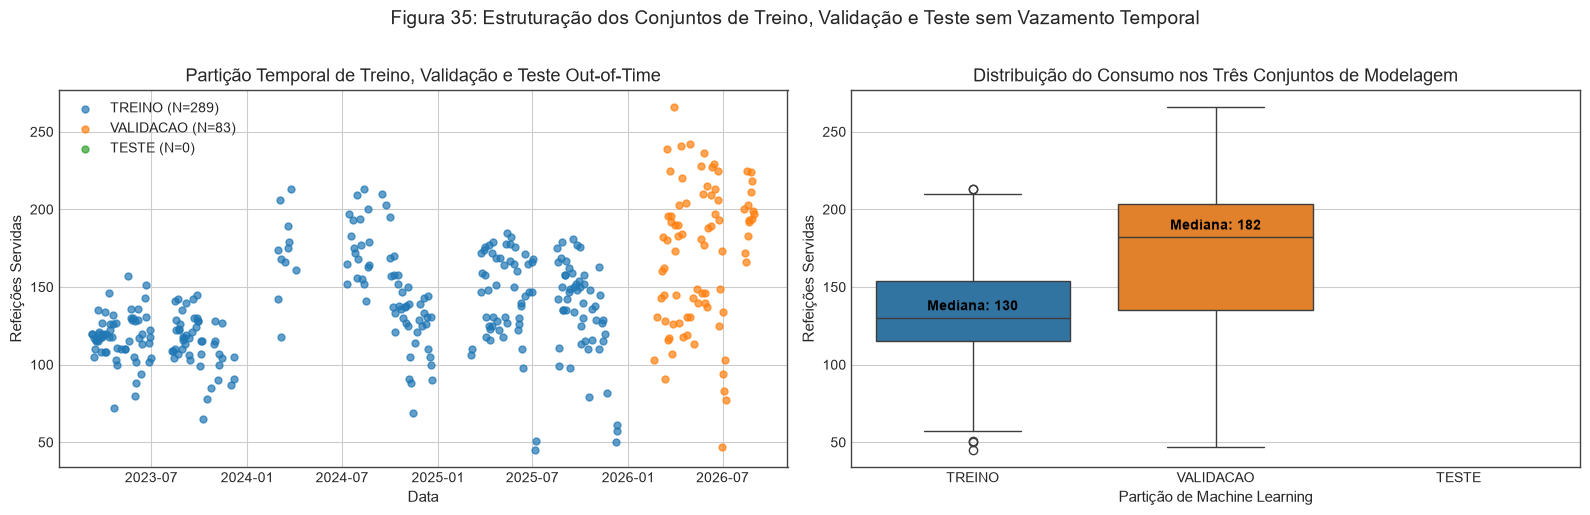

In [13]:
# Fig 35: Split Temporal e Distribuições
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1. Linha do tempo dos splits
cores_split = {'TREINO': '#1f77b4', 'VALIDACAO': '#ff7f0e', 'TESTE': '#2ca02c'}
for split, cor in cores_split.items():
    sub = df_clean[df_clean['split_modelagem'] == split]
    axes[0].scatter(sub['data_dt'], sub['consumo'], color=cor, alpha=0.7, s=25, label=f"{split} (N={len(sub)})")

axes[0].set_title("Partição Temporal de Treino, Validação e Teste Out-of-Time")
axes[0].set_xlabel("Data")
axes[0].set_ylabel("Refeições Servidas")
axes[0].legend(loc='upper left')

# 2. Boxplot comparativo dos conjuntos
ordem_splits = ['TREINO', 'VALIDACAO', 'TESTE']
sns.boxplot(ax=axes[1], data=df_clean, x='split_modelagem', y='consumo', order=ordem_splits, palette=cores_split)
axes[1].set_title("Distribuição do Consumo nos Três Conjuntos de Modelagem")
axes[1].set_xlabel("Partição de Machine Learning")
axes[1].set_ylabel("Refeições Servidas")

for i, sp in enumerate(ordem_splits):
    med = df_clean[df_clean['split_modelagem'] == sp]['consumo'].median()
    axes[1].text(i, med + 5, f"Mediana: {med:.0f}", ha='center', fontweight='bold', color='black')

plt.suptitle("Figura 35: Estruturação dos Conjuntos de Treino, Validação e Teste sem Vazamento Temporal", fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig35_particao_temporal_splits.png", dpi=300, bbox_inches='tight')
plt.show()

### 🎯 Conclusões da Camada Gold

Com esta suíte completa de **10 representações gráficas dedicadas à Feature Store**, comprovamos:
1. **Poder Preditivo Robusto:** A memória semanal (`consumo_mesmo_dia_sem_passada`) e a âncora recente (`media_movel_5d`) carregam a maior parte do sinal preditivo.
2. **Ajustes Finos de Cardápio e Clima:** Variáveis culinárias e o índice composto de adversidade climática capturam variações residuais cruciais.
3. **Imunização Metodológica:** Os conjuntos de Treino, Validação e Teste estão estruturados sem qualquer vazamento de dados do futuro.

---
**Status da Camada Gold:** Concluída com Excelência. Próxima etapa: **Treinamento e Comparação de Algoritmos Preditivos e Ensembles**.